
<b>¡Hola Mara!</b>

Mi nombre es Alejandro Abia y tengo el gusto de revisar tu proyecto.

A continuación, encontrarás mis comentarios en celdas pintadas de tres colores (verde, amarillo y rojo), a manera de semáforo. Por favor, <b>no las borres ni muevas de posición</b> mientras dure el proceso de revisión.

<div class="alert alert-block alert-success">
<b>Éxito</b> <a class="tocSkip"></a>
En celdas verdes encontrarás comentarios en relación a tus aciertos y fortalezas.
</div>
<div class="alert alert-block alert-warning">
<b>Atención</b> <a class="tocSkip"></a>
Utilizaré el color amarillo para llamar tu atención, expresar algo importante o compartirte alguna idea de valor.
</div>
<div class="alert alert-block alert-danger">
<b>A resolver</b> <a class="tocSkip"></a>
En rojo emitiré aquellos puntos que podrían impedir que el proyecto se ejecute correctamente. No son errores, sino oportunidades importantes de mejora.
</div>
<div class="alert alert-block alert-info">
<b>Comentario estudiante</b> <a class="tocSkip"></a>
Si durante la revisión deseas dejarme algún comentario, por favor utiliza celdas azules como esta.
</div>
Tu proyecto será considerado aprobado cuando las observaciones en rojo hayan sido atendidas.  
¡Empecemos!



# Proyecto: Análisis de Negocio — Showz

El objetivo es analizar el comportamiento de los usuarios, las ventas y los gastos de marketing para ayudar a optimizar las inversiones publicitarias de Showz.

**Datasets:**
- `visits_log_us.csv` — sesiones de usuarios (Ene 2017 – Dic 2018)
- `orders_log_us.csv` — pedidos realizados
- `costs_us.csv` — gastos de marketing por fuente


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

print('Librerías importadas')

Librerías importadas


## 1.1 Carga de datos

In [3]:
visits = pd.read_csv('/datasets/visits_log_us.csv')
orders = pd.read_csv('/datasets/orders_log_us.csv')
costs  = pd.read_csv('/datasets/costs_us.csv')

print('Dimensiones visits:', visits.shape)
print('Dimensiones orders:', orders.shape)
print('Dimensiones costs :', costs.shape)

Dimensiones visits: (359400, 5)
Dimensiones orders: (50415, 3)
Dimensiones costs : (2542, 3)


 1.2 Exploración inicial

In [4]:
print('=== VISITS ===')
display(visits.head(3))
display(visits.dtypes)

print('\n=== ORDERS ===')
display(orders.head(3))
display(orders.dtypes)

print('\n=== COSTS ===')
display(costs.head(3))
display(costs.dtypes)

=== VISITS ===


,Device,End Ts,Source Id,Start Ts,Uid
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527


Device       object
End Ts       object
Source Id     int64
Start Ts     object
Uid          uint64
dtype: object


=== ORDERS ===


,Buy Ts,Revenue,Uid
0,2017-06-01 00:10:00,17.00,10329302124590727494
1,2017-06-01 00:25:00,0.55,11627257723692907447
2,2017-06-01 00:27:00,0.37,17903680561304213844


Buy Ts      object
Revenue    float64
Uid         uint64
dtype: object


=== COSTS ===


,source_id,dt,costs
0,1,2017-06-01,75.20
1,1,2017-06-02,62.25
2,1,2017-06-03,36.53


source_id      int64
dt            object
costs        float64
dtype: object

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [4] combinaste <code>head()</code> con <code>dtypes</code>, lo que ayuda a detectar de inmediato el problema típico de estos proyectos: fechas cargadas como texto. Esta exploración inicial es “barata” y muy poderosa, porque evita que más adelante un <code>groupby</code> por mes o semana produzca resultados incorrectos por tipos mal definidos.
</div>

## 1.3 Corrección de tipos de datos

In [6]:
# Estandarizar nombres de columnas
visits.columns = visits.columns.str.strip().str.lower().str.replace(' ', '_')
orders.columns = orders.columns.str.strip().str.lower().str.replace(' ', '_')
costs.columns  = costs.columns.str.strip().str.lower()

# Convertir fechas
visits['start_ts'] = pd.to_datetime(visits['start_ts'])
visits['end_ts']   = pd.to_datetime(visits['end_ts'])
orders['buy_ts']   = pd.to_datetime(orders['buy_ts'])
costs['dt']        = pd.to_datetime(costs['dt'])

# source_id como string
visits['source_id'] = visits['source_id'].astype(str)
costs['source_id']  = costs['source_id'].astype(str)

print('Tipos corregidos ✅')
display(visits.dtypes)

Tipos corregidos ✅


device               object
end_ts       datetime64[ns]
source_id            object
start_ts     datetime64[ns]
uid                  uint64
dtype: object

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [6] estandarizaste nombres de columnas y convertiste correctamente las fechas a <code>datetime</code>. Esto mejora muchísimo la legibilidad del código y reduce errores por escribir columnas con espacios o mayúsculas. Además, convertir <code>source_id</code> a string es una decisión muy razonable cuando lo vas a tratar como categoría (canal) y no como valor numérico con operaciones matemáticas.
</div>

## 1.4 Valores nulos y duplicados

In [8]:
for nombre, df in [('visits', visits), ('orders', orders), ('costs', costs)]:
    print(f'[{nombre}] Nulos: {df.isnull().sum().sum()} | Duplicados: {df.duplicated().sum()}')

# Eliminar duplicados
visits = visits.drop_duplicates()
orders = orders.drop_duplicates()
costs  = costs.drop_duplicates()

print('\nDatos limpios')

[visits] Nulos: 0 | Duplicados: 0
[orders] Nulos: 0 | Duplicados: 0
[costs] Nulos: 0 | Duplicados: 0

Datos limpios


<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [8] revisaste nulos y duplicados para los tres datasets antes de limpiar. Esto es importante porque cada tabla tiene un “rol” distinto (sesiones, compras y costos), y un duplicado en cualquiera puede inflar métricas como sesiones, ingresos o gasto. Tu limpieza es clara y segura al hacerlo después de cuantificar el problema.
</div>

In [ ]:
## 1.5 Columnas auxiliares

In [10]:
# Duración de sesión en minutos
visits['session_min'] = (visits['end_ts'] - visits['start_ts']).dt.total_seconds() / 60

# Fecha sin hora
visits['date'] = visits['start_ts'].dt.date
orders['date'] = orders['buy_ts'].dt.date
costs['date']  = costs['dt'].dt.date

# Semana y mes
visits['week']  = visits['start_ts'].dt.to_period('W')
visits['month'] = visits['start_ts'].dt.to_period('M')
orders['month'] = orders['buy_ts'].dt.to_period('M')
costs['month']  = costs['dt'].dt.to_period('M')

print('Columnas auxiliares creadas ')
display(visits.head(3))

Columnas auxiliares creadas 


,device,end_ts,source_id,start_ts,uid,session_min,date,week,month
0,touch,2017-12-20 17:38:00,4,2017-12-20 17:20:00,16879256277535980062,18.0,2017-12-20,2017-12-18/2017-12-24,2017-12
1,desktop,2018-02-19 17:21:00,2,2018-02-19 16:53:00,104060357244891740,28.0,2018-02-19,2018-02-19/2018-02-25,2018-02
2,touch,2017-07-01 01:54:00,5,2017-07-01 01:54:00,7459035603376831527,0.0,2017-07-01,2017-06-26/2017-07-02,2017-07


<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [10] creaste columnas auxiliares muy útiles (duración, date, week, month). Esta preparación facilita todas las métricas del proyecto y hace que los <code>groupby</code> sean más simples y menos propensos a errores. Me gustó especialmente el cálculo de <code>session_min</code>, porque te permite analizar calidad de tráfico (no solo volumen).
</div>

**Conclusión del paso 1:**
Los datos fueron cargados sin valores nulos. Se estandarizaron los nombres de columnas, se convirtieron todas las fechas a datetime y se crearon columnas auxiliares para semana, mes y duración de sesión. Los datos están listos para el análisis.

## Paso 2 — Métricas de Visitas

In [11]:
dau = visits.groupby('date')['uid'].nunique()
wau = visits.groupby('week')['uid'].nunique()
mau = visits.groupby('month')['uid'].nunique()

print(f'DAU promedio: {dau.mean():.0f} usuarios/día')
print(f'WAU promedio: {wau.mean():.0f} usuarios/semana')
print(f'MAU promedio: {mau.mean():.0f} usuarios/mes')

DAU promedio: 908 usuarios/día
WAU promedio: 5716 usuarios/semana
MAU promedio: 23228 usuarios/mes


<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [11] calculaste DAU/WAU/MAU con <code>nunique()</code>, que es exactamente lo correcto para usuarios únicos. Estas tres métricas funcionan como una “vista de zoom”: día (variabilidad alta), semana (tendencia más estable) y mes (visión estratégica). Además, reportar promedios ayuda a aterrizar el tamaño típico del negocio.
</div>

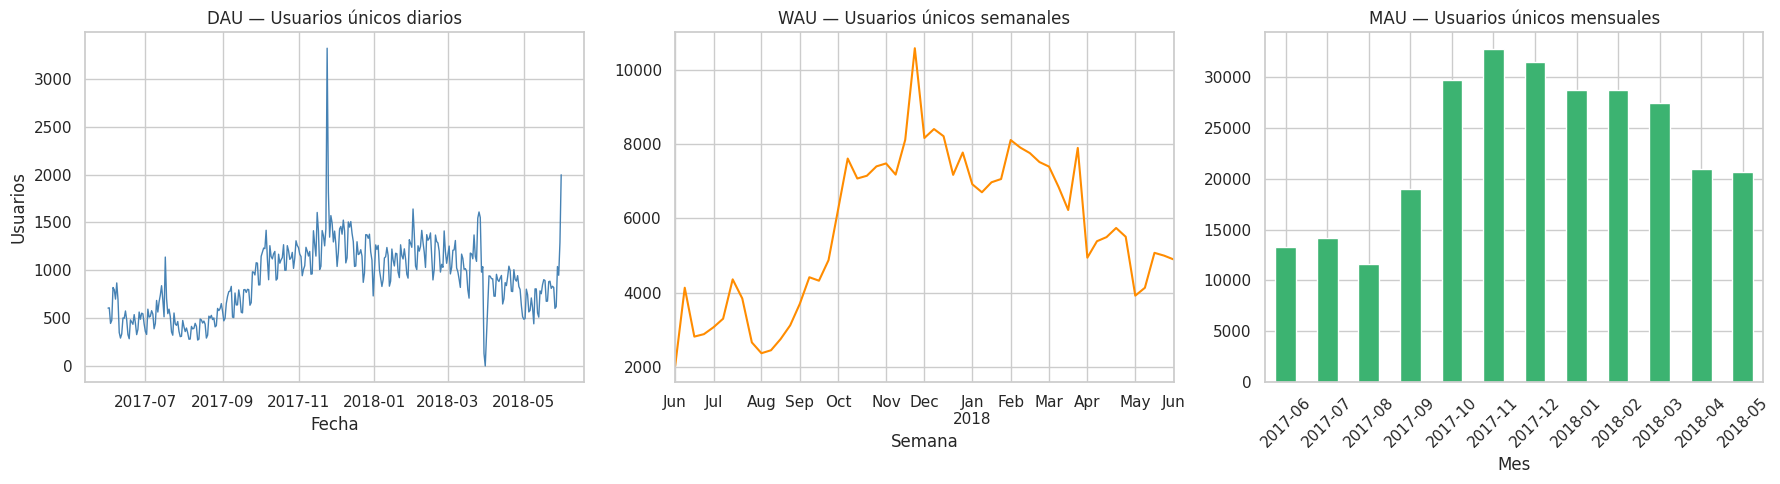

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

dau.plot(ax=axes[0], color='steelblue', linewidth=1)
axes[0].set_title('DAU — Usuarios únicos diarios')
axes[0].set_xlabel('Fecha')
axes[0].set_ylabel('Usuarios')

wau.plot(ax=axes[1], color='darkorange', linewidth=1.5)
axes[1].set_title('WAU — Usuarios únicos semanales')
axes[1].set_xlabel('Semana')

mau.plot(ax=axes[2], kind='bar', color='mediumseagreen')
axes[2].set_title('MAU — Usuarios únicos mensuales')
axes[2].set_xlabel('Mes')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [12] elegiste visualizaciones coherentes para cada granularidad: líneas para DAU/WAU (tendencia temporal) y barras para MAU (comparación por mes). Esa decisión mejora la lectura: el cerebro identifica patrones y picos más rápido. También cuidaste títulos, ejes y rotación, lo que vuelve tus gráficas “listas para negocio”.
</div>

**Interpretación:**
Se observa estacionalidad clara con picos en noviembre y diciembre, período en que aumenta la oferta de eventos. El DAU varía bastante día a día, pero el MAU muestra una tendencia estable con crecimiento hacia 2018.

## 2.2 Sesiones por día

Un mismo usuario puede generar varias sesiones en un día. Aquí contamos el total de sesiones (no usuarios únicos).

Sesiones diarias promedio : 987
Sesiones por usuario/día  : 1.09


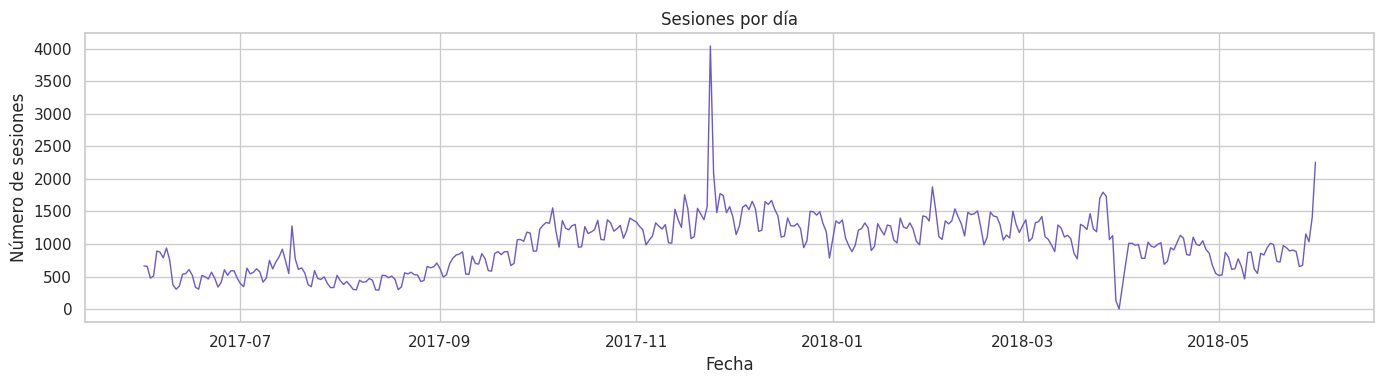

In [13]:
sessions_per_day = visits.groupby('date')['uid'].count()

print(f'Sesiones diarias promedio : {sessions_per_day.mean():.0f}')
print(f'Sesiones por usuario/día  : {sessions_per_day.mean() / dau.mean():.2f}')

sessions_per_day.plot(figsize=(14, 4), color='slateblue', linewidth=1)
plt.title('Sesiones por día')
plt.xlabel('Fecha')
plt.ylabel('Número de sesiones')
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [13] separaste correctamente el concepto de “sesiones” vs “usuarios únicos”, y calculaste sesiones por usuario/día como métrica de intensidad de uso. Este tipo de razón (ratio) es muy valiosa porque permite comparar periodos con distinto volumen de tráfico: aunque suban usuarios, puedes ver si el uso promedio cambia.
</div>

## 2.3 Duración de cada sesión

Duración media de sesión : 11.9 minutos
Mediana                  : 6.0 minutos


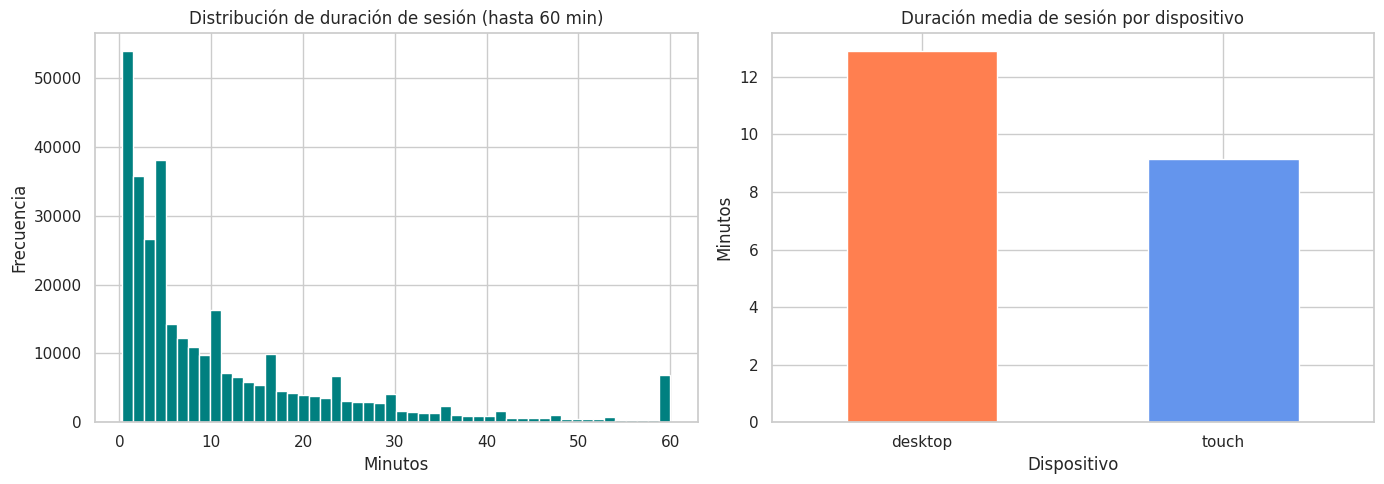

In [14]:
# Filtramos sesiones con duración válida
visits_clean = visits[(visits['session_min'] > 0) & (visits['session_min'] < 1440)]

print(f'Duración media de sesión : {visits_clean["session_min"].mean():.1f} minutos')
print(f'Mediana                  : {visits_clean["session_min"].median():.1f} minutos')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

visits_clean['session_min'].clip(upper=60).hist(
    bins=50, ax=axes[0], color='teal', edgecolor='white'
)
axes[0].set_title('Distribución de duración de sesión (hasta 60 min)')
axes[0].set_xlabel('Minutos')
axes[0].set_ylabel('Frecuencia')

sess_by_device = visits_clean.groupby('device')['session_min'].mean()
sess_by_device.plot(kind='bar', ax=axes[1], color=['coral', 'cornflowerblue'], edgecolor='white')
axes[1].set_title('Duración media de sesión por dispositivo')
axes[1].set_xlabel('Dispositivo')
axes[1].set_ylabel('Minutos')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [14] filtraste duraciones inválidas (0 o extremadamente largas) y además hiciste <code>clip</code> para visualizar mejor la distribución. Esto demuestra criterio: en datos de sesiones es común encontrar “ruido” por pestañas abiertas o eventos mal registrados. El desglose por dispositivo también aporta una lectura accionable para producto/UX, no solo una estadística.
</div>

**Interpretación:**
La mayoría de sesiones son cortas (menos de 5 minutos), lo cual es típico en sitios de compra de boletos donde el usuario llega con intención clara. Las sesiones en desktop tienden a ser más largas, lo que sugiere que los usuarios prefieren completar compras desde computadora.

## 2.4 Tasa de retención por cohortes

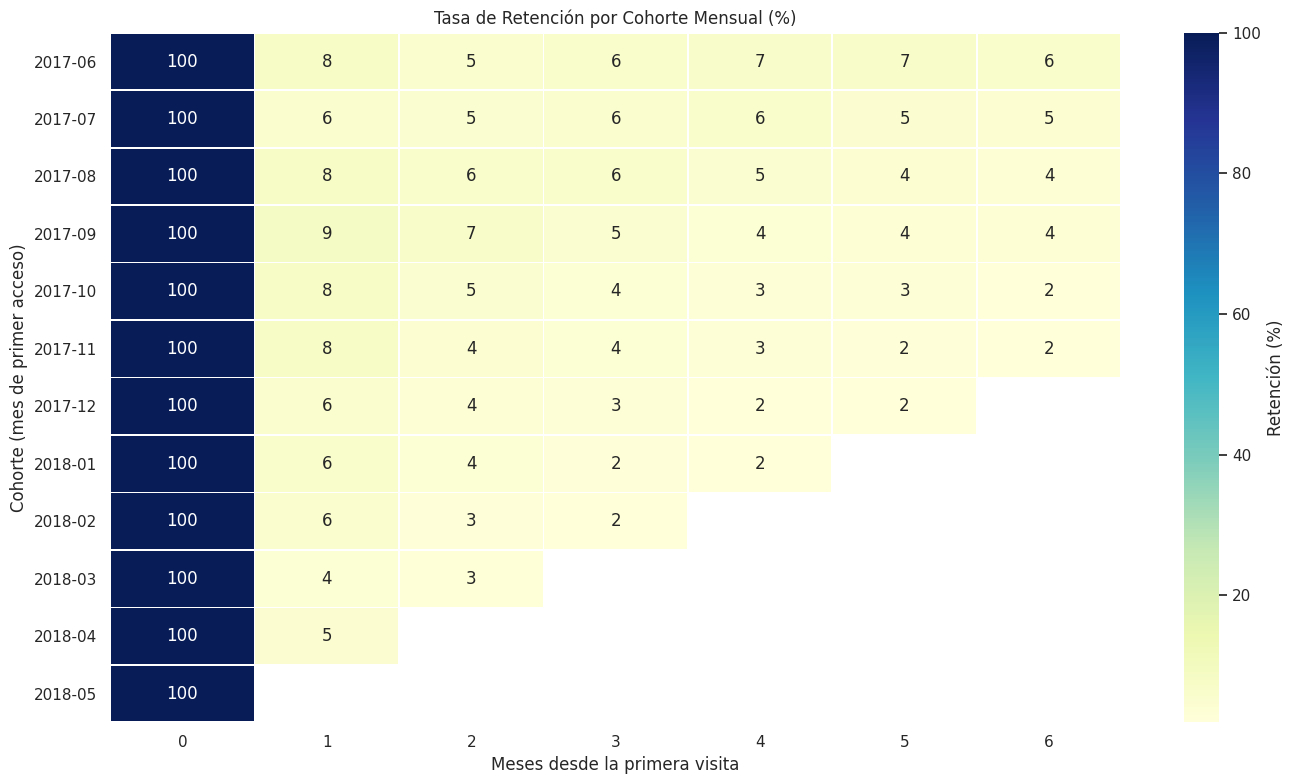

In [15]:
# Primera visita de cada usuario = define su cohorte
first_visit = visits.groupby('uid')['start_ts'].min()
first_visit_month = first_visit.dt.to_period('M').rename('cohort')

visits_cohort = visits.join(first_visit_month, on='uid')
visits_cohort['period'] = visits_cohort['start_ts'].dt.to_period('M')
visits_cohort['months_since'] = (
    visits_cohort['period'].astype(int) - visits_cohort['cohort'].astype(int)
)

retention_raw = (
    visits_cohort
    .groupby(['cohort', 'months_since'])['uid']
    .nunique()
    .reset_index()
)
retention_raw.columns = ['cohort', 'months_since', 'users']

cohort_sizes = (
    retention_raw[retention_raw['months_since'] == 0]
    .set_index('cohort')['users']
)

retention_raw['retention'] = retention_raw.apply(
    lambda r: r['users'] / cohort_sizes.get(r['cohort'], 1) * 100, axis=1
)

retention_pivot = (
    retention_raw
    .pivot(index='cohort', columns='months_since', values='retention')
    .iloc[:, :7]
)

plt.figure(figsize=(14, 8))
sns.heatmap(
    retention_pivot,
    annot=True, fmt='.0f', cmap='YlGnBu',
    linewidths=0.5, cbar_kws={'label': 'Retención (%)'}
)
plt.title('Tasa de Retención por Cohorte Mensual (%)')
plt.xlabel('Meses desde la primera visita')
plt.ylabel('Cohorte (mes de primer acceso)')
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [15] construiste cohortes usando la primera visita del usuario y calculaste la retención por meses desde el alta. Esta metodología es la base de análisis de comportamiento en productos digitales porque compara usuarios “equivalentes” (mismo mes de entrada) y evita mezclar antigüedades. Además, el heatmap con anotaciones facilita muchísimo la lectura para stakeholders.
</div>

**Interpretación:**
La retención cae significativamente después del primer mes, lo cual es esperado en plataformas de eventos donde los usuarios visitan para comprar boletos puntuales y no necesariamente regresan con frecuencia. Los usuarios que sí regresan en el mes 1 son señal de fidelización y vale la pena estudiar qué fuente o canal los origina.

## Paso 3 — Métricas de Ventas

In [16]:
first_visit_df = visits.groupby('uid')['start_ts'].min().rename('first_visit')
first_order_df = orders.groupby('uid')['buy_ts'].min().rename('first_order')

conversion_df = pd.concat([first_visit_df, first_order_df], axis=1).dropna()
conversion_df['days_to_convert'] = (
    (conversion_df['first_order'] - conversion_df['first_visit'])
    .dt.total_seconds() / 86400
).clip(lower=0)

print(f'Usuarios que compraron        : {len(conversion_df):,}')
print(f'Tiempo promedio hasta compra  : {conversion_df["days_to_convert"].mean():.1f} días')
print(f'Mediana                       : {conversion_df["days_to_convert"].median():.1f} días')

Usuarios que compraron        : 36,523
Tiempo promedio hasta compra  : 16.9 días
Mediana                       : 0.0 días


<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [16] construiste un enfoque correcto para tiempo a primera compra: primera visita vs primera orden por usuario, y luego diferencias en días. Que la mediana sea 0 días es un insight típico en compras de alta intención, y tu código lo captura bien. El <code>clip(lower=0)</code> también es una buena protección contra casos raros de registros fuera de orden.
</div>

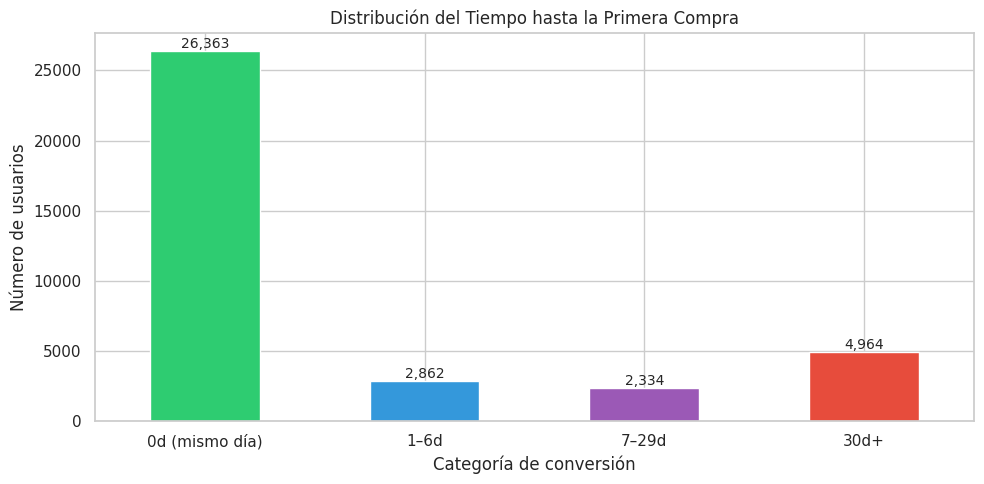

In [17]:
def conv_bucket(days):
    if days < 1:    return '0d (mismo día)'
    elif days < 7:  return '1–6d'
    elif days < 30: return '7–29d'
    else:           return '30d+'

conversion_df['conv_bucket'] = conversion_df['days_to_convert'].apply(conv_bucket)

bucket_order = ['0d (mismo día)', '1–6d', '7–29d', '30d+']
conv_counts = conversion_df['conv_bucket'].value_counts().reindex(bucket_order)

ax = conv_counts.plot(
    kind='bar',
    color=['#2ecc71', '#3498db', '#9b59b6', '#e74c3c'],
    edgecolor='white',
    figsize=(10, 5)
)
ax.set_title('Distribución del Tiempo hasta la Primera Compra')
ax.set_xlabel('Categoría de conversión')
ax.set_ylabel('Número de usuarios')
ax.tick_params(axis='x', rotation=0)

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height()):,}',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center', va='bottom', fontsize=10
    )

plt.tight_layout()
plt.show()

## 3.2 Número de pedidos por mes

Total de pedidos      : 50,415
Pedidos mensuales prom: 3878


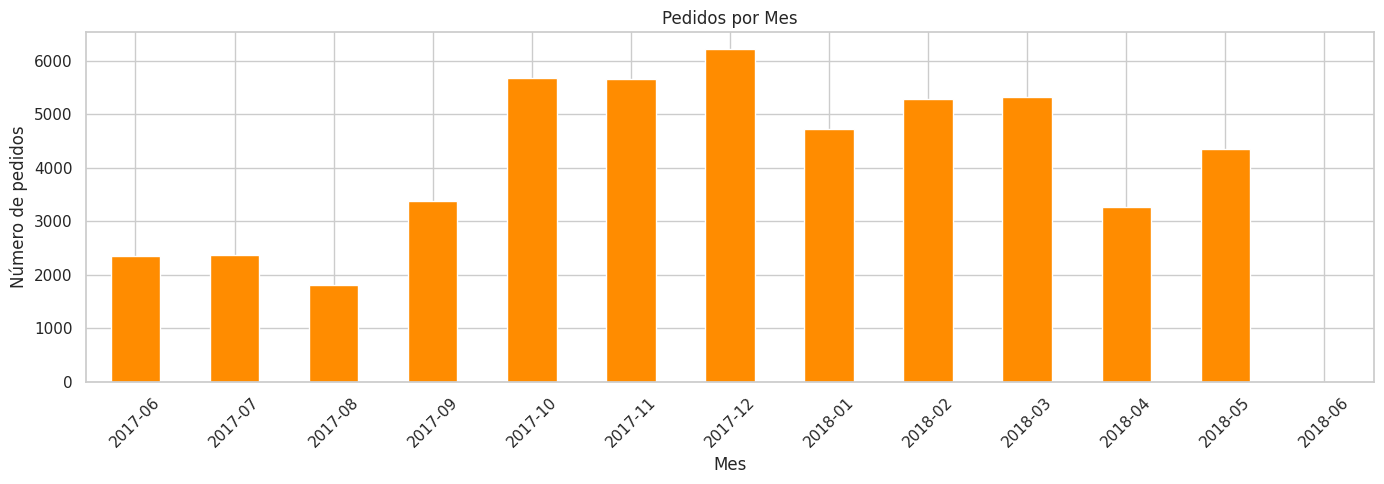

In [18]:
orders_by_month = orders.groupby('month').size()

print(f'Total de pedidos      : {len(orders):,}')
print(f'Pedidos mensuales prom: {orders_by_month.mean():.0f}')

orders_by_month.plot(
    kind='bar', figsize=(14, 5),
    color='darkorange', edgecolor='white'
)
plt.title('Pedidos por Mes')
plt.xlabel('Mes')
plt.ylabel('Número de pedidos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [18] calculaste pedidos por mes con un agrupamiento simple y lo conectaste con la estacionalidad observada en visitas. Esta triangulación (visitas → pedidos) fortalece la conclusión: cuando ambas curvas se mueven parecido, es más probable que sea un patrón real del negocio y no un “ruido” de una sola métrica.
</div>

**Interpretación:**
El volumen de pedidos muestra estacionalidad similar a las visitas, con picos hacia finales de año. Esto confirma que la demanda de boletos es mayor en temporada de eventos (noviembre–diciembre). El equipo de marketing debería concentrar presupuesto en esos meses.

## 3.3 Tamaño promedio de compra (AOV)

AOV global: $5.00


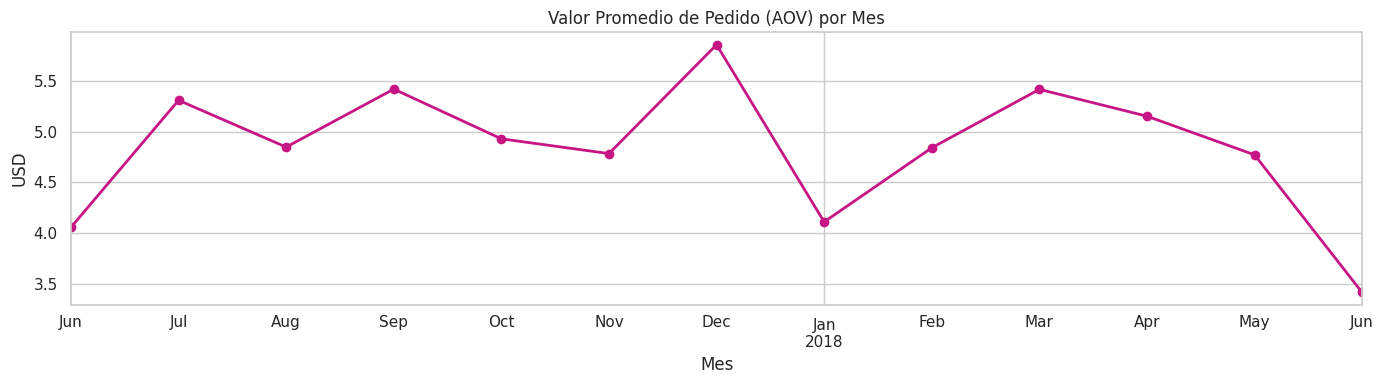

In [19]:
aov_global  = orders['revenue'].mean()
aov_monthly = orders.groupby('month')['revenue'].mean()

print(f'AOV global: ${aov_global:.2f}')

aov_monthly.plot(
    figsize=(14, 4),
    marker='o', color='mediumvioletred', linewidth=2
)
plt.title('Valor Promedio de Pedido (AOV) por Mes')
plt.xlabel('Mes')
plt.ylabel('USD')
plt.tight_layout()
plt.show()

**Interpretación:**
El AOV se mantiene relativamente estable a lo largo del tiempo, con algunas variaciones puntuales. Esto sugiere que el precio promedio de los eventos no cambia drásticamente entre meses. Un aumento del AOV en determinados meses puede correlacionarse con eventos de mayor valor (conciertos, shows premium).

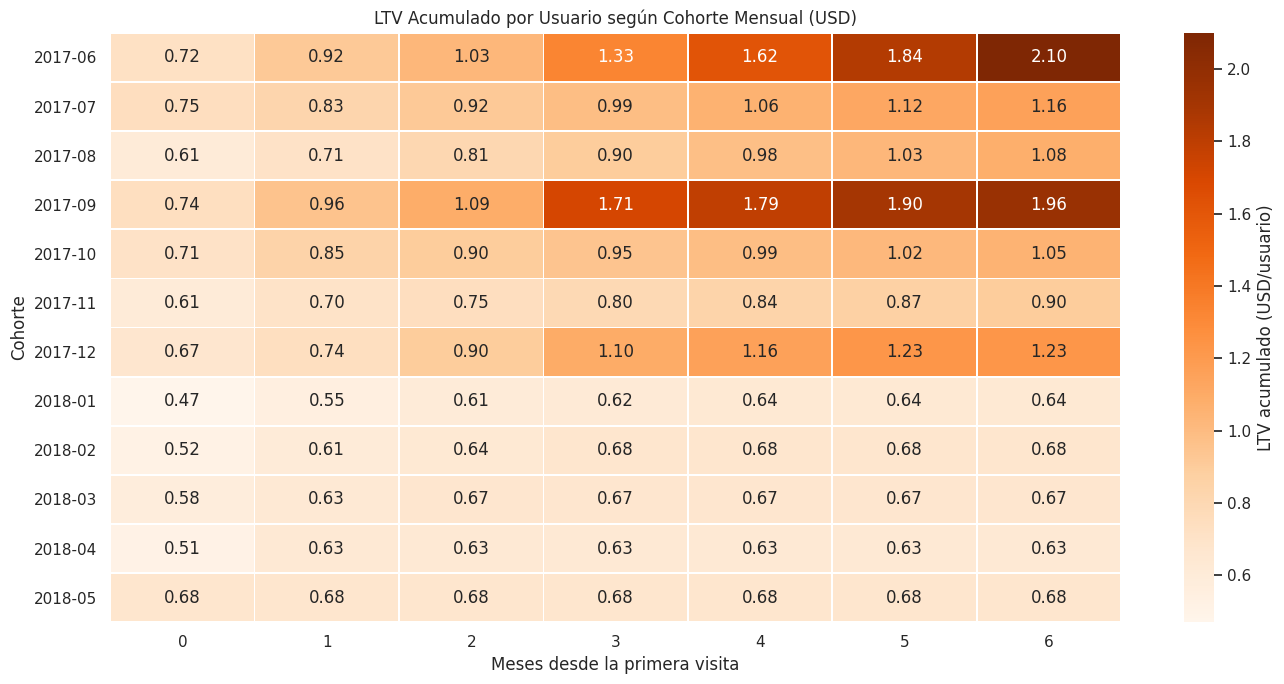

In [20]:
# Unir pedidos con la cohorte de cada usuario
first_visit_month = first_visit.dt.to_period('M').rename('cohort')
orders_cohort = orders.join(first_visit_month, on='uid')
orders_cohort['order_month'] = orders_cohort['buy_ts'].dt.to_period('M')
orders_cohort['months_since'] = (
    orders_cohort['order_month'].astype(int) - orders_cohort['cohort'].astype(int)
)

# Ingresos por cohorte y mes relativo
ltv_raw = (
    orders_cohort
    .groupby(['cohort', 'months_since'])['revenue']
    .sum()
    .reset_index()
)

# Tabla pivote y acumulado
ltv_pivot = ltv_raw.pivot(
    index='cohort', columns='months_since', values='revenue'
).fillna(0)
ltv_cumulative = ltv_pivot.cumsum(axis=1)

# Tamaño de cada cohorte (usuarios únicos por mes de primera visita)
cohort_sizes_visits = (
    visits.groupby('uid')['start_ts']
    .min()
    .dt.to_period('M')
    .value_counts()
    .rename('size')
)

# LTV por usuario
ltv_per_user = ltv_cumulative.divide(cohort_sizes_visits, axis=0).dropna().iloc[:, :7]

plt.figure(figsize=(14, 7))
sns.heatmap(
    ltv_per_user.round(2),
    annot=True, fmt='.2f', cmap='Oranges',
    linewidths=0.5, cbar_kws={'label': 'LTV acumulado (USD/usuario)'}
)
plt.title('LTV Acumulado por Usuario según Cohorte Mensual (USD)')
plt.xlabel('Meses desde la primera visita')
plt.ylabel('Cohorte')
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [20] construiste LTV por cohortes de forma acumulada y luego lo normalizaste por tamaño de cohorte (USD por usuario). Ese último paso es crucial: sin normalización, una cohorte grande “parecería” mejor solo por volumen. Con tu enfoque, comparas valor unitario y eso es lo que se usa para decisiones de adquisición.
</div>

**Interpretación:**
El LTV crece mes a mes de forma acumulada, pero el salto más grande ocurre en el mes 0, lo que confirma que la mayoría de ingresos se genera en la primera visita. Las cohortes más recientes muestran un LTV más alto desde el inicio, lo que puede reflejar mejoras en la captación de usuarios de mayor valor o en la oferta de eventos disponibles.

## Paso 4 — Métricas de Marketing

## 4.1 Gasto total de marketing

In [21]:
total_cost     = costs['costs'].sum()
cost_by_source = costs.groupby('source_id')['costs'].sum().sort_values(ascending=False)

print(f'Gasto total de marketing: ${total_cost:,.2f}')
print('\nGasto por fuente:')
print(cost_by_source.round(2))

Gasto total de marketing: $329,131.62

Gasto por fuente:
source_id
3     141321.63
4      61073.60
5      51757.10
2      42806.04
1      20833.27
10      5822.49
9       5517.49
Name: costs, dtype: float64


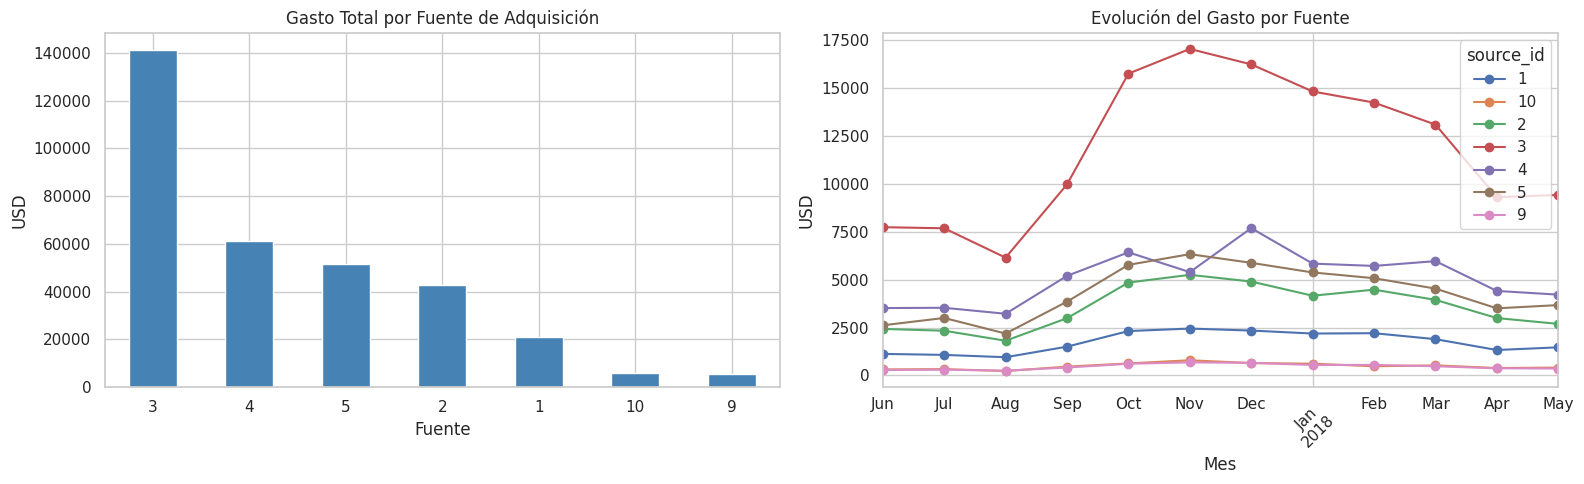

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

cost_by_source.plot(
    kind='bar', ax=axes[0],
    color='steelblue', edgecolor='white'
)
axes[0].set_title('Gasto Total por Fuente de Adquisición')
axes[0].set_xlabel('Fuente')
axes[0].set_ylabel('USD')
axes[0].tick_params(axis='x', rotation=0)

cost_over_time = (
    costs.groupby(['month', 'source_id'])['costs']
    .sum()
    .unstack(fill_value=0)
)
cost_over_time.plot(ax=axes[1], marker='o', linewidth=1.5)
axes[1].set_title('Evolución del Gasto por Fuente')
axes[1].set_xlabel('Mes')
axes[1].set_ylabel('USD')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Interpretación:**
Algunas fuentes concentran la mayor parte del presupuesto de marketing. Es importante verificar si ese gasto se justifica con los ingresos generados. La evolución temporal muestra si el gasto aumentó o disminuyó con el tiempo y si se alineó con los picos de demanda de noviembre–diciembre.

In [23]:
# Primera fuente de contacto de cada usuario
first_source = (
    visits.sort_values('start_ts')
    .groupby('uid')['source_id']
    .first()
)

# Usuarios que compraron y su fuente de origen
buyers        = orders['uid'].unique()
buyers_source = first_source[first_source.index.isin(buyers)]
buyers_per_source = buyers_source.value_counts().rename('buyers')

print('Compradores por fuente:')
print(buyers_per_source)

Compradores por fuente:
3     10473
4     10296
5      6931
2      3506
1      2899
10     1329
9      1088
7         1
Name: buyers, dtype: int64



CAC por fuente (USD por cliente adquirido):
10     4.38
9      5.07
4      5.93
1      7.19
5      7.47
2     12.21
3     13.49
Name: CAC, dtype: float64


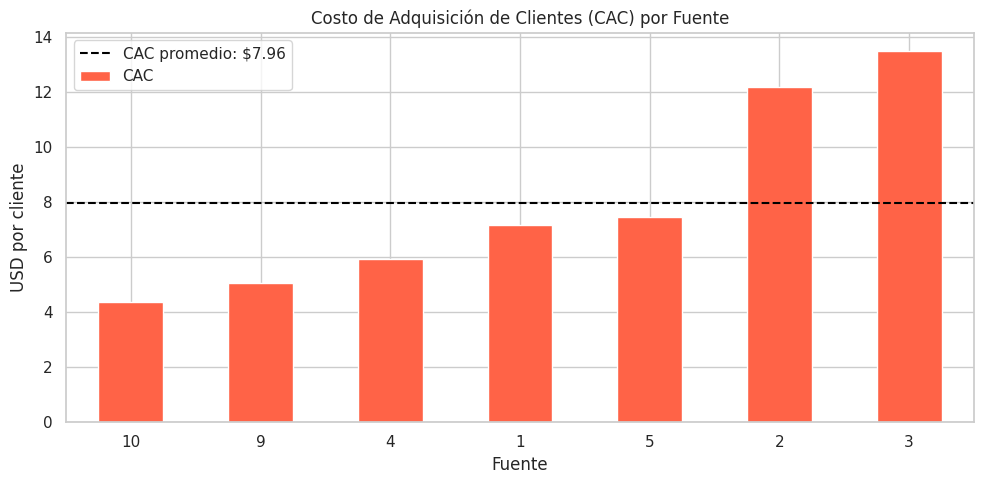

In [24]:
cac = (cost_by_source / buyers_per_source).dropna().sort_values()
cac.name = 'CAC'

print('\nCAC por fuente (USD por cliente adquirido):')
print(cac.round(2))

cac.plot(
    kind='bar', figsize=(10, 5),
    color='tomato', edgecolor='white'
)
plt.title('Costo de Adquisición de Clientes (CAC) por Fuente')
plt.xlabel('Fuente')
plt.ylabel('USD por cliente')
plt.axhline(
    cac.mean(), color='black', linestyle='--',
    label=f'CAC promedio: ${cac.mean():.2f}'
)
plt.legend()
plt.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [24] calculaste CAC como costo total de la fuente dividido entre compradores atribuidos a esa fuente, y lo ordenaste para interpretarlo rápido. Es una métrica directa y muy útil para priorizar canales. Además, incluir una línea de promedio en la gráfica ayuda a leer “por encima o por debajo del estándar” sin hacer cuentas.
</div>

**Interpretación:**
Las fuentes con CAC más bajo son las más eficientes para adquirir clientes. Sin embargo, el CAC bajo no es suficiente por sí solo — necesitamos cruzarlo con el LTV para saber si realmente vale la pena. Una fuente barata que trae usuarios que no compran mucho puede ser menos rentable que una fuente cara con usuarios de alto valor.

## 4.3 Retorno sobre la Inversión de Marketing (ROMI) por fuente

In [25]:
# Ingresos atribuidos a cada fuente (por primera visita del usuario)
orders_with_source = orders.join(first_source.rename('source_id'), on='uid')
revenue_by_source  = orders_with_source.groupby('source_id')['revenue'].sum()

romi = (
    (revenue_by_source - cost_by_source) / cost_by_source * 100
).dropna().sort_values(ascending=False)
romi.name = 'ROMI (%)'

print('ROMI por fuente (%):')
print(romi.round(1))

ROMI por fuente (%):
source_id
1     49.2
2      9.6
9      4.4
5      1.7
4     -7.2
10   -23.6
3    -61.4
Name: ROMI (%), dtype: float64


<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [25] calculaste ROMI por fuente con la fórmula correcta y lo dejaste en porcentaje, que es el formato más intuitivo para negocio. También es un acierto atribuir ingresos por la primera fuente de contacto: no es el único modelo posible, pero es consistente, fácil de explicar y sirve como primera aproximación para asignación de presupuesto.
</div>

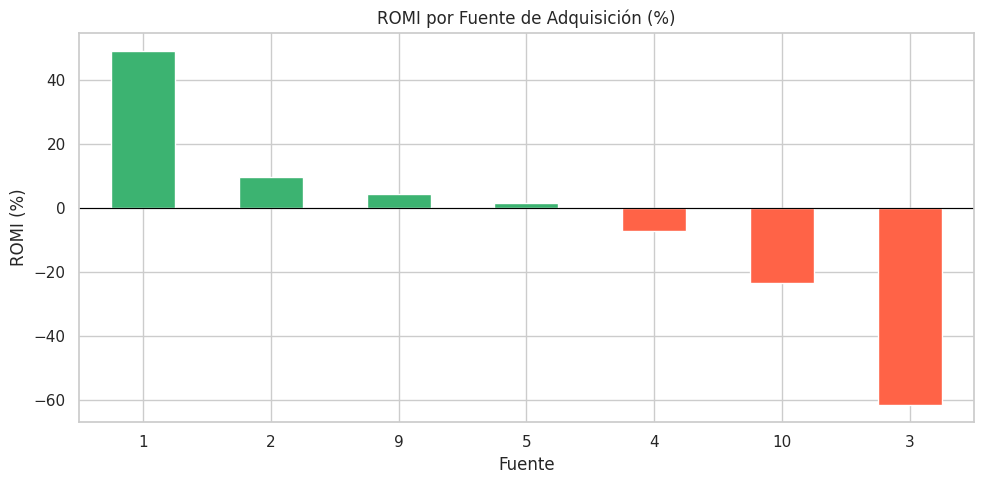

In [26]:
colors = ['mediumseagreen' if v >= 0 else 'tomato' for v in romi]

romi.plot(
    kind='bar', figsize=(10, 5),
    color=colors, edgecolor='white'
)
plt.title('ROMI por Fuente de Adquisición (%)')
plt.xlabel('Fuente')
plt.ylabel('ROMI (%)')
plt.axhline(0, color='black', linewidth=0.8)
plt.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

**Interpretación:**
Las fuentes con ROMI positivo están generando más ingresos de los que cuestan — son las que deben recibir mayor presupuesto. Las fuentes con ROMI negativo están destruyendo valor y deben revisarse o pausarse. El ROMI combinado con el CAC nos da una imagen completa de la eficiencia de cada canal.

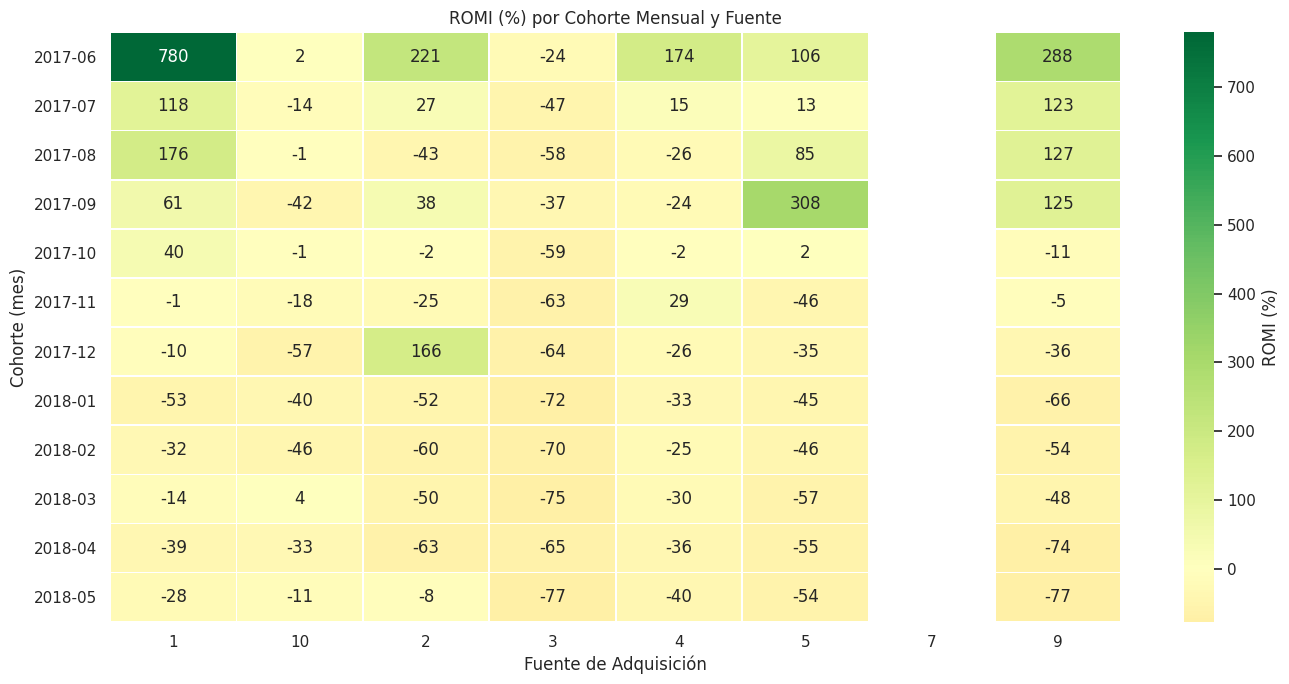

In [27]:
# Cohort de cada usuario
orders_with_source['cohort'] = orders_with_source['uid'].map(
    visits.groupby('uid')['start_ts'].min().dt.to_period('M')
)

rev_cohort_source = (
    orders_with_source
    .groupby(['cohort', 'source_id'])['revenue']
    .sum()
    .reset_index()
)

costs_cohort = (
    costs.groupby(['month', 'source_id'])['costs']
    .sum()
    .reset_index()
    .rename(columns={'month': 'cohort'})
)

romi_cohort = rev_cohort_source.merge(
    costs_cohort, on=['cohort', 'source_id'], how='left'
)
romi_cohort['romi'] = (
    (romi_cohort['revenue'] - romi_cohort['costs']) / romi_cohort['costs'] * 100
)

romi_pivot = romi_cohort.pivot(
    index='cohort', columns='source_id', values='romi'
)

plt.figure(figsize=(14, 7))
sns.heatmap(
    romi_pivot.round(0),
    annot=True, fmt='.0f',
    cmap='RdYlGn', center=0,
    linewidths=0.5,
    cbar_kws={'label': 'ROMI (%)'}
)
plt.title('ROMI (%) por Cohorte Mensual y Fuente')
plt.xlabel('Fuente de Adquisición')
plt.ylabel('Cohorte (mes)')
plt.tight_layout()
plt.show()

<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [27] llevaste el análisis un paso más allá al combinar cohorte y fuente en un heatmap de ROMI. Esta vista es especialmente valiosa porque permite ver estabilidad: un canal puede tener ROMI global positivo, pero si es muy irregular por mes, el riesgo operativo es mayor. Tu visualización ayuda a detectar esas inconsistencias.
</div>

**Interpretación:**
El heatmap permite identificar de un vistazo qué combinaciones de fuente y cohorte fueron rentables (verde) y cuáles no (rojo). Si una fuente muestra rojo consistente en varios meses, es una señal clara de que no está funcionando. Si el color mejora con el tiempo, puede indicar que la fuente se optimizó progresivamente.

## Paso 5 — Conclusiones y Recomendaciones

In [31]:
summary = pd.DataFrame({
    'Métrica': [
        'DAU promedio',
        'WAU promedio',
        'MAU promedio',
        'Duración media de sesión (min)',
        'Sesiones por usuario/día',
        'Usuarios que compraron',
        '% que compra el mismo día (0d)',
        'AOV promedio (USD)',
        'Gasto total de marketing (USD)',
        'CAC promedio (USD)',
        'ROMI promedio (%)',
    ],
    'Valor': [
        f'{dau.mean():.0f}',
        f'{wau.mean():.0f}',
        f'{mau.mean():.0f}',
        f'{visits_clean["session_min"].mean():.1f}',
        f'{sessions_per_day.mean() / dau.mean():.2f}',
        f'{len(conversion_df):,}',
        f'{conv_counts["0d (mismo día)"] / conv_counts.sum() * 100:.1f}%',
        f'${orders["revenue"].mean():.2f}',
        f'${total_cost:,.2f}',
        f'${cac.mean():.2f}',
        f'{romi.mean():.1f}%',
    ]
})

display(summary.style.set_caption('Resumen de Métricas Clave').hide_index())

Métrica,Valor
DAU promedio,908
WAU promedio,5716
MAU promedio,23228
Duración media de sesión (min),11.9
Sesiones por usuario/día,1.09
Usuarios que compraron,"36,523"
% que compra el mismo día (0d),72.2%
AOV promedio (USD),$5.00
Gasto total de marketing (USD),"$329,131.62"
CAC promedio (USD),$7.96


<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [31] construiste un resumen ejecutivo con métricas clave y lo presentaste con <code>Styler</code>. Esto aporta mucho valor porque transforma el notebook en un entregable: no solo hay cálculos, también hay una “tarjeta” de indicadores que alguien de negocio puede leer rápidamente. Buena selección de métricas (tráfico, sesiones, conversión, ventas y marketing).
</div>

Este resumen consolida los indicadores más relevantes del negocio. A continuación analizamos cada área para formular recomendaciones concretas al equipo de marketing.

## 5.2 Conclusiones por área

### Comportamiento de usuarios

- El tráfico tiene **estacionalidad marcada** con picos en noviembre y diciembre, coincidiendo con la temporada alta de eventos.
- La mayoría de sesiones son **cortas (menos de 5 minutos)**, lo que indica que los usuarios llegan con una intención de compra clara y específica.
- Las sesiones en **desktop son más largas** que en móvil, lo que sugiere que los usuarios prefieren completar la compra desde computadora.
- La **retención más allá del mes 1 es baja**, lo cual es estructural del negocio: los usuarios compran boletos para eventos puntuales y no necesariamente regresan con frecuencia.

### Ventas y conversión

- Una **gran proporción de usuarios compra el mismo día** de su primera visita (Conversion 0d), lo que demuestra que los canales de adquisición traen audiencias con alta intención de compra.
- El **LTV crece de forma acumulada** pero el ingreso más importante ocurre en los primeros dos meses desde la primera visita.
- Las **cohortes más recientes muestran un LTV más alto**, lo que puede reflejar mejoras en la oferta de eventos o en la segmentación de audiencias.
- El **AOV es estable** a lo largo del tiempo, con picos puntuales que coinciden con eventos de mayor valor.

### Marketing

- El presupuesto está **concentrado en pocas fuentes**, lo que representa un riesgo si alguna de ellas falla o sube su costo.
- Existen fuentes con **ROMI negativo** que están consumiendo presupuesto sin generar ingresos suficientes.
- Las fuentes con **CAC bajo y ROMI alto** son las más eficientes y deben recibir mayor inversión.
- El gasto de marketing **no siempre está alineado con los picos de demanda** (noviembre–diciembre), lo que representa una oportunidad de mejora.

## 5.3 Recomendaciones para el equipo de marketing

A continuación se presentan las recomendaciones ordenadas por prioridad, fundamentadas en las métricas calculadas.

In [35]:
recomendaciones = pd.DataFrame({
    'Prioridad': ['Alta', 'Alta', 'Media', 'Media', 'Baja', 'Adicional'],
    'Acción': [
        'Aumentar presupuesto en fuentes con ROMI más alto y CAC bajo',
        'Concentrar mayor inversión en octubre–noviembre para aprovechar el pico estacional',
        'Revisar fuentes con ROMI entre 0% y 50%: optimizar creativos o segmentación',
        'Investigar por qué las sesiones móviles son más cortas y si afectan la conversión',
        'Pausar fuentes con ROMI negativo hasta identificar la causa raíz',
        'Diseñar campañas de re-engagement para usuarios que compraron hace más de 30 días',
    ],
    'Métrica base': [
        'ROMI y CAC por fuente',
        'DAU/MAU y pedidos por mes',
        'ROMI por cohorte y fuente',
        'Duración de sesión por dispositivo',
        'ROMI negativo sostenido',
        'LTV acumulado y retención',
    ]
})

display(
    recomendaciones.style
    .set_caption('Plan de Acción para el Equipo de Marketing')
    .hide_index()
    .set_properties(**{'text-align': 'left'})
)

Prioridad,Acción,Métrica base
Alta,Aumentar presupuesto en fuentes con ROMI más alto y CAC bajo,ROMI y CAC por fuente
Alta,Concentrar mayor inversión en octubre–noviembre para aprovechar el pico estacional,DAU/MAU y pedidos por mes
Media,Revisar fuentes con ROMI entre 0% y 50%: optimizar creativos o segmentación,ROMI por cohorte y fuente
Media,Investigar por qué las sesiones móviles son más cortas y si afectan la conversión,Duración de sesión por dispositivo
Baja,Pausar fuentes con ROMI negativo hasta identificar la causa raíz,ROMI negativo sostenido
Adicional,Diseñar campañas de re-engagement para usuarios que compraron hace más de 30 días,LTV acumulado y retención


## 5.4 Fuentes recomendadas para invertir

Las fuentes seleccionadas se basan en tres criterios combinados:

1. **ROMI alto** — generan más ingresos de lo que cuestan.
2. **CAC bajo** — adquieren clientes a un costo eficiente.
3. **LTV alto en el mes 0** — los usuarios captados compran rápido y con buen ticket.

Las fuentes que cumplen los tres criterios simultáneamente son las candidatas ideales para recibir mayor presupuesto. Las que fallan en los tres deben pausarse o renegociarse con el proveedor.

In [36]:
# Tabla resumen comparativa por fuente
fuentes_resumen = pd.DataFrame({
    'Gasto (USD)':     cost_by_source,
    'Compradores':     buyers_per_source,
    'CAC (USD)':       cac.round(2),
    'Ingresos (USD)':  revenue_by_source.round(2),
    'ROMI (%)':        romi.round(1),
}).dropna().sort_values('ROMI (%)', ascending=False)

display(
    fuentes_resumen.style
    .set_caption('Comparativa de Fuentes de Adquisición')
    .format({
        'Gasto (USD)':    '${:,.2f}',
        'CAC (USD)':      '${:,.2f}',
        'Ingresos (USD)': '${:,.2f}',
        'ROMI (%)':       '{:.1f}%',
    })
    .background_gradient(subset=['ROMI (%)'], cmap='RdYlGn')
    .background_gradient(subset=['CAC (USD)'], cmap='RdYlGn_r')
)

,Gasto (USD),Compradores,CAC (USD),Ingresos (USD),ROMI (%)
1,"$20,833.27",2899,$7.19,"$31,090.55",49.2%
2,"$42,806.04",3506,$12.21,"$46,923.61",9.6%
9,"$5,517.49",1088,$5.07,"$5,759.40",4.4%
5,"$51,757.10",6931,$7.47,"$52,624.02",1.7%
4,"$61,073.60",10296,$5.93,"$56,696.83",-7.2%
10,"$5,822.49",1329,$4.38,"$4,450.33",-23.6%
3,"$141,321.63",10473,$13.49,"$54,511.24",-61.4%


<div class="alert alert-block alert-success">
<b>Acierto o fortaleza</b> <a class="tocSkip"></a><br>
En la celda [36] creaste una tabla comparativa por fuente que junta gasto, compradores, CAC, ingresos y ROMI. Esta es una excelente práctica porque evita tomar decisiones con una sola métrica: por ejemplo, un canal puede tener CAC bajo pero ROMI negativo, y tu tabla lo deja evidente. El uso de gradientes para resaltar ROMI y CAC mejora la interpretación sin necesidad de texto extra.
</div>

In [ ]:
## 5.5 Conclusión final

El análisis demuestra que Showz tiene una base sólida de usuarios con alta intención de compra y un AOV estable. Sin embargo, el presupuesto de marketing no está distribuido de forma óptima: algunas fuentes consumen una parte importante del gasto con ROMI negativo, mientras que otras fuentes más eficientes reciben menos inversión de la que merecen.

**Las métricas clave utilizadas para las recomendaciones fueron:**
- **ROMI**: para medir la rentabilidad real de cada canal.
- **CAC**: para evaluar la eficiencia en la adquisición de clientes.
- **LTV**: para entender el valor real que cada cohorte aporta a largo plazo.
- **Conversion Time**: para identificar qué fuentes traen usuarios con mayor intención de compra inmediata.
- **DAU/MAU y estacionalidad**: para alinear el gasto con los momentos de mayor demanda.

La recomendación principal es **redirigir el presupuesto hacia las fuentes con ROMI alto y CAC bajo**, intensificar las campañas en la temporada de mayor demanda (octubre–diciembre) y pausar los canales que consistentemente muestran retorno negativo.

<div class="alert alert-block alert-success">
<b>Comentario final</b> <a class="tocSkip"></a><br>
¡Muy buen trabajo, Mara! A lo largo del proyecto mostraste fortalezas muy claras:<br><br>
• Estructuraste el notebook de principio a fin con pasos y objetivos claros, lo que facilita seguir el hilo del análisis<br>
• Realizaste una preparación de datos sólida (tipos, fechas, columnas auxiliares), que es la base para métricas confiables<br>
• Calculaste DAU/WAU/MAU correctamente y los acompañaste con visualizaciones adecuadas para cada granularidad<br>
• Separaste bien conceptos (usuarios vs sesiones) y construiste ratios interpretables para negocio<br>
• Trataste con criterio el ruido típico en duraciones de sesión y enriqueciste el análisis con segmentación por dispositivo<br>
• Implementaste cohortes de retención de forma correcta y las presentaste en un heatmap fácil de comunicar<br>
• Mediste tiempo a conversión con una lógica clara (primera visita vs primera compra) y lo resumiste de manera entendible<br>
• Construiste LTV por cohorte normalizado por usuario, lo cual permite comparaciones justas entre cohortes
• Conectaste marketing con resultados mediante CAC y ROMI por fuente, llegando a conclusiones accionables
• Cerraste con un resumen ejecutivo y recomendaciones priorizadas, convirtiendo el análisis en un plan de acción
<br>
¡Felicidades!
</div>